# Install All Libraries

In [17]:
# Install in specific order
!pip install floret==0.10.3
!pip install textacy==0.12.0
!pip install gensim
!python -m spacy download en_core_web_sm

  Using cached floret-0.10.3.tar.gz (70 kB)
  Installing build dependencies ... done
ERROR: Operation cancelled by user
  Getting requirements to build wheel ... Requirement already satisfied: textacy==0.12.0 in /usr/local/lib/python3.13/dist-packages (0.12.0)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 99.0 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


 Import All Libraries

In [1]:
import textacy
import textacy.datasets
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings
warnings.filterwarnings('ignore')

print("Textacy version:", textacy.__version__)
print("✅ All libraries imported!")

Textacy version: 0.12.0
✅ All libraries imported!


Load Dataset

In [2]:
scotus = textacy.datasets.SupremeCourt()
scotus.download()

print("✅ Dataset loaded!")

100%|██████████| 111M/111M [00:01<00:00, 99.6MB/s]

✅ Dataset loaded!


 Check One Record (Verification)

In [3]:
# Just check 1 record to verify everything works
for record in scotus.records(limit=1):
    print("Case Name :", record.meta.get('case_name'))
    print("Issue Area:", record.meta.get('issue_area'))
    print("Text      :", record.text[:200])
    print("Meta Keys :", list(record.meta.keys()))

Case Name : HALLIBURTON OIL WELL CEMENTING CO. v. WALKER et al., DOING BUSINESS AS DEPTHOGRAPH CO.
Issue Area: 8
Text      : [ Halliburton Oil Well Cementing Co. v. Walker Mr.Earl Babcock, of Duncan, Okl. (Harry C. Robb, of Washington, D.C., on the brief), for petitioner.
 Mr. Harold W. Mattingly, of Los Angeles, Cal., for 
Meta Keys : ['issue', 'issue_area', 'n_min_votes', 'case_name', 'maj_opinion_author', 'decision_date', 'decision_direction', 'n_maj_votes', 'us_cite_id', 'argument_date']


Convert All Records to DataFrame

In [4]:
print("Loading all records...")

data = []

for record in scotus.records():
    issue_area = record.meta.get('issue_area')
    text = record.text

    # Only keep valid records
    if issue_area is not None and text and len(text.strip()) > 100:
        data.append({
            'case_name'          : record.meta.get('case_name', 'Unknown'),
            'text'               : text,
            'issue_area'         : int(issue_area),
            'issue_code'         : record.meta.get('issue', None),
            'decision_date'      : record.meta.get('decision_date', None),
            'decision_direction' : record.meta.get('decision_direction', None),
        })

df = pd.DataFrame(data)

print(f"✅ Total usable records : {len(df)}")
print(f"   Shape               : {df.shape}")
print(f"   Columns             : {df.columns.tolist()}")

Loading all records...
✅ Total usable records : 8398
   Shape               : (8398, 6)
   Columns             : ['case_name', 'text', 'issue_area', 'issue_code', 'decision_date', 'decision_direction']


Label Mapping

In [5]:
issue_area_labels = {
    1  : 'Criminal Procedure',
    2  : 'Civil Rights',
    3  : 'First Amendment',
    4  : 'Due Process',
    5  : 'Privacy',
    6  : 'Attorneys',
    7  : 'Unions',
    8  : 'Economic Activity',
    9  : 'Judicial Power',
    10 : 'Federalism',
    11 : 'Interstate Relations',
    12 : 'Federal Taxation',
    13 : 'Miscellaneous',
    14 : 'Private Action'
}

df['issue_area_name'] = df['issue_area'].map(issue_area_labels)

print("Label Distribution:")
print("="*45)
print(df['issue_area_name'].value_counts())
print(f"\nTotal categories: {df['issue_area'].nunique()}")

Label Distribution:
issue_area_name
Criminal Procedure      1923
Economic Activity       1667
Civil Rights            1356
Judicial Power          1135
First Amendment          658
Federalism               367
Unions                   345
Due Process              335
Federal Taxation         304
Privacy                  110
Attorneys                 98
Interstate Relations      58
Miscellaneous             19
Private Action             1
Name: count, dtype: int64

Total categories: 15


 Visualize Label Distribution

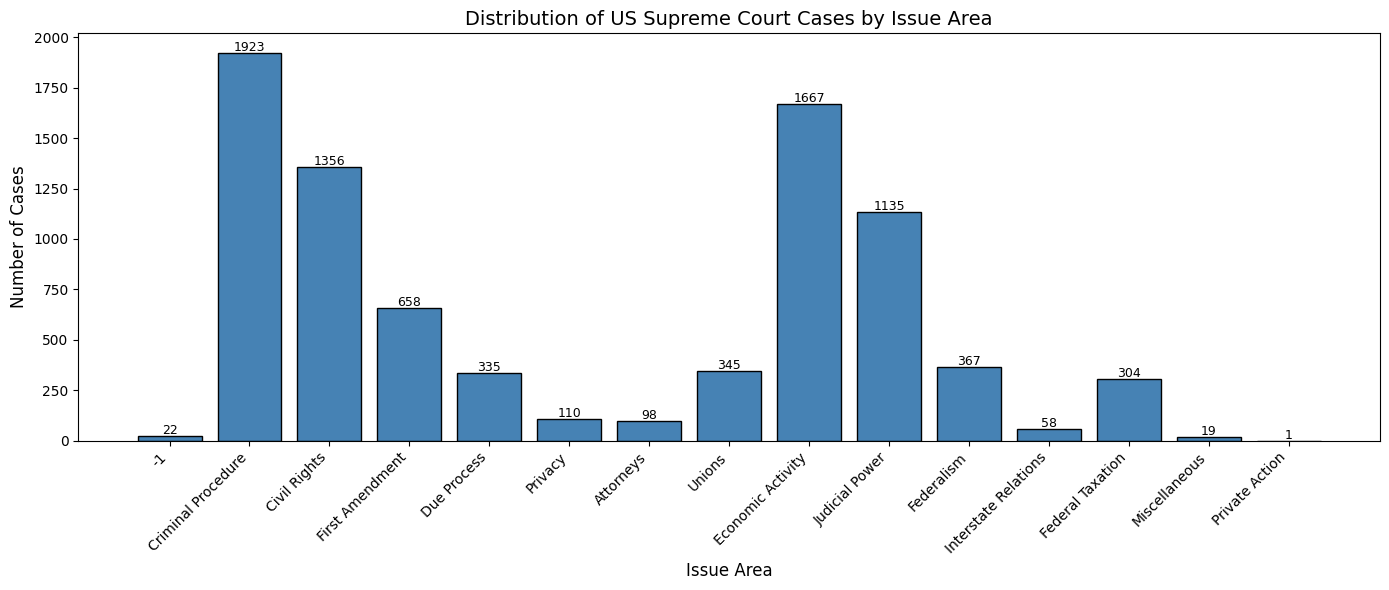

✅ Plot saved!


In [6]:
plt.figure(figsize=(14, 6))

counts = df['issue_area'].value_counts().sort_index()
labels_for_plot = [issue_area_labels.get(i, str(i))
                   for i in counts.index]

bars = plt.bar(labels_for_plot,
               counts.values,
               color='steelblue',
               edgecolor='black')

plt.xlabel("Issue Area", fontsize=12)
plt.ylabel("Number of Cases", fontsize=12)
plt.title("Distribution of US Supreme Court Cases by Issue Area",
          fontsize=14)
plt.xticks(rotation=45, ha='right')

for bar, count in zip(bars, counts.values):
    plt.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 10,
             str(count),
             ha='center', fontsize=9)

plt.tight_layout()
plt.savefig('label_distribution.png', dpi=150)
plt.show()

print("✅ Plot saved!")

Define Preprocessing Function

In [7]:
import spacy
import re

nlp = spacy.load("en_core_web_sm")

def preprocess_text(text):
    # Lowercase
    text = text.lower()

    # Remove special characters
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Remove extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    # Tokenize with spacy
    doc = nlp(text, disable=['parser', 'ner'])

    # Keep meaningful tokens
    tokens = [
        token.lemma_
        for token in doc
        if not token.is_stop
        and not token.is_punct
        and not token.is_space
        and len(token.text) > 2
    ]

    return tokens

# Test it
test_tokens = preprocess_text(df['text'].iloc[0][:300])
print("✅ Preprocessing function defined!")
print(f"   Sample tokens: {test_tokens[:10]}")

✅ Preprocessing function defined!
   Sample tokens: ['halliburton', 'oil', 'cementing', 'walker', 'earl', 'babcock', 'duncan', 'okl', 'harry', 'robb']


Preprocess All Documents

In [8]:

print("Preprocessing all documents...")
print("Please wait...\n")

processed_texts = []

for i, text in enumerate(df['text']):
    tokens = preprocess_text(text)
    processed_texts.append(tokens)

    if (i+1) % 500 == 0:
        print(f"  Progress: {i+1}/{len(df)} done...")

df['tokens'] = processed_texts

print(f"\n✅ Preprocessing complete!")
print(f"   Sample: {processed_texts[0][:10]}")

Preprocessing all documents...
Please wait...

  Progress: 500/8398 done...
  Progress: 1000/8398 done...
  Progress: 1500/8398 done...
  Progress: 2000/8398 done...
  Progress: 2500/8398 done...
  Progress: 3000/8398 done...
  Progress: 3500/8398 done...
  Progress: 4000/8398 done...
  Progress: 4500/8398 done...
  Progress: 5000/8398 done...
  Progress: 5500/8398 done...
  Progress: 6000/8398 done...
  Progress: 6500/8398 done...
  Progress: 7000/8398 done...
  Progress: 7500/8398 done...
  Progress: 8000/8398 done...

✅ Preprocessing complete!
   Sample: ['halliburton', 'oil', 'cementing', 'walker', 'earl', 'babcock', 'duncan', 'okl', 'harry', 'robb']


Train Test Split

In [10]:
from sklearn.model_selection import train_test_split
from collections import Counter

# Check class distribution first
print("Class distribution BEFORE filtering:")
print("="*45)
counter = Counter(y)
for label, count in sorted(counter.items()):
    name = issue_area_labels.get(label, str(label))
    print(f"  {label:>3} - {name:<25} : {count}")

# Remove classes with less than 2 samples
print("\nFiltering rare classes...")
valid_indices = [
    i for i, label in enumerate(y)
    if counter[label] >= 2
]

X_filtered = [X[i] for i in valid_indices]
y_filtered = [y[i] for i in valid_indices]

print(f"\nBefore filtering : {len(X)} samples")
print(f"After filtering  : {len(X_filtered)} samples")
print(f"Removed          : {len(X) - len(X_filtered)} samples")

# Now split
X_train, X_test, y_train, y_test = train_test_split(
    X_filtered, y_filtered,
    test_size=0.2,
    random_state=42,
    stratify=y_filtered
)

print(f"\n✅ Split complete!")
print(f"   Training samples : {len(X_train)}")
print(f"   Testing samples  : {len(X_test)}")
print(f"   Classes          : {sorted(set(y_filtered))}")

Class distribution BEFORE filtering:
   -1 - -1                        : 22
    1 - Criminal Procedure        : 1923
    2 - Civil Rights              : 1356
    3 - First Amendment           : 658
    4 - Due Process               : 335
    5 - Privacy                   : 110
    6 - Attorneys                 : 98
    7 - Unions                    : 345
    8 - Economic Activity         : 1667
    9 - Judicial Power            : 1135
   10 - Federalism                : 367
   11 - Interstate Relations      : 58
   12 - Federal Taxation          : 304
   13 - Miscellaneous             : 19
   14 - Private Action            : 1

Filtering rare classes...

Before filtering : 8398 samples
After filtering  : 8397 samples
Removed          : 1 samples

✅ Split complete!
   Training samples : 6717
   Testing samples  : 1680
   Classes          : [-1, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]


 LDA Model

In [11]:
from gensim import corpora, models

print("Building dictionary...")
dictionary = corpora.Dictionary(X_train)
dictionary.filter_extremes(no_below=5, no_above=0.7)

train_corpus = [dictionary.doc2bow(text) for text in X_train]
test_corpus  = [dictionary.doc2bow(text) for text in X_test]

print(f"Dictionary size : {len(dictionary)}")
print(f"Training corpus : {len(train_corpus)}")

print("\nTraining LDA model...")
NUM_TOPICS = 20

lda_model = models.LdaModel(
    corpus      = train_corpus,
    id2word     = dictionary,
    num_topics  = NUM_TOPICS,
    random_state= 42,
    passes      = 10,
    alpha       = 'auto',
    eta         = 'auto'
)

print("✅ LDA training complete!")

Building dictionary...
Dictionary size : 31469
Training corpus : 6717

Training LDA model...
✅ LDA training complete!


LDA + Logistic Regression

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Convert to topic vectors
def get_topic_vector(bow):
    topic_dist = lda_model.get_document_topics(
        bow, minimum_probability=0
    )
    return [prob for _, prob in sorted(topic_dist)]

print("Converting to topic vectors...")
X_train_lda = np.array([get_topic_vector(bow)
                         for bow in train_corpus])
X_test_lda  = np.array([get_topic_vector(bow)
                         for bow in test_corpus])

print("Training Logistic Regression...")
lr_lda = LogisticRegression(max_iter=1000, random_state=42)
lr_lda.fit(X_train_lda, y_train)

y_pred_lda = lr_lda.predict(X_test_lda)
acc_lda    = accuracy_score(y_test, y_pred_lda)

print(f"\n{'='*45}")
print(f"✅ LDA + LR Accuracy: {acc_lda:.4f} ({acc_lda*100:.2f}%)")
print(f"{'='*45}")
print(classification_report(
    y_test, y_pred_lda,
    target_names=[issue_area_labels.get(i, str(i))
                  for i in sorted(set(y_test))]
))

Converting to topic vectors...
Training Logistic Regression...

✅ LDA + LR Accuracy: 0.6435 (64.35%)
                      precision    recall  f1-score   support

                  -1       0.00      0.00      0.00         4
  Criminal Procedure       0.76      0.91      0.83       385
        Civil Rights       0.57      0.62      0.59       271
     First Amendment       0.68      0.80      0.74       132
         Due Process       0.25      0.01      0.03        67
             Privacy       0.25      0.05      0.08        22
           Attorneys       0.00      0.00      0.00        20
              Unions       0.63      0.72      0.68        69
   Economic Activity       0.62      0.73      0.67       333
      Judicial Power       0.54      0.55      0.55       227
          Federalism       0.25      0.01      0.03        73
Interstate Relations       0.00      0.00      0.00        12
    Federal Taxation       0.67      0.57      0.62        61
       Miscellaneous       0.0

Doc2Vec Model

In [13]:
from gensim.models.doc2vec import Doc2Vec, TaggedDocument

# Tag documents
train_tagged = [
    TaggedDocument(words=text, tags=[str(i)])
    for i, text in enumerate(X_train)
]

print("Training Doc2Vec...")
doc2vec = Doc2Vec(
    vector_size = 100,
    min_count   = 2,
    epochs      = 40,
    workers     = 4
)

doc2vec.build_vocab(train_tagged)
doc2vec.train(
    train_tagged,
    total_examples = doc2vec.corpus_count,
    epochs         = doc2vec.epochs
)

print("✅ Doc2Vec training complete!")

Training Doc2Vec...
✅ Doc2Vec training complete!


Doc2Vec + Logistic Regression

In [14]:
print("Getting document vectors...")
X_train_d2v = np.array([
    doc2vec.dv[str(i)] for i in range(len(X_train))
])
X_test_d2v = np.array([
    doc2vec.infer_vector(text) for text in X_test
])

print("Training Logistic Regression...")
lr_d2v = LogisticRegression(max_iter=1000, random_state=42)
lr_d2v.fit(X_train_d2v, y_train)

y_pred_d2v = lr_d2v.predict(X_test_d2v)
acc_d2v    = accuracy_score(y_test, y_pred_d2v)

print(f"\n{'='*45}")
print(f"✅ Doc2Vec + LR Accuracy: {acc_d2v:.4f} ({acc_d2v*100:.2f}%)")
print(f"{'='*45}")
print(classification_report(
    y_test, y_pred_d2v,
    target_names=[issue_area_labels.get(i, str(i))
                  for i in sorted(set(y_test))]
))

Getting document vectors...
Training Logistic Regression...

✅ Doc2Vec + LR Accuracy: 0.6899 (68.99%)
                      precision    recall  f1-score   support

                  -1       0.14      0.25      0.18         4
  Criminal Procedure       0.80      0.85      0.82       385
        Civil Rights       0.69      0.69      0.69       271
     First Amendment       0.72      0.86      0.78       132
         Due Process       0.55      0.39      0.46        67
             Privacy       0.46      0.59      0.52        22
           Attorneys       0.52      0.60      0.56        20
              Unions       0.74      0.86      0.79        69
   Economic Activity       0.74      0.65      0.70       333
      Judicial Power       0.56      0.51      0.53       227
          Federalism       0.57      0.41      0.48        73
Interstate Relations       0.38      0.50      0.43        12
    Federal Taxation       0.65      0.87      0.74        61
       Miscellaneous       0.

Compare Models

      FINAL MODEL COMPARISON
Model                            Accuracy
---------------------------------------------
LDA + Logistic Regression          0.6435
Doc2Vec + Logistic Regression      0.6899


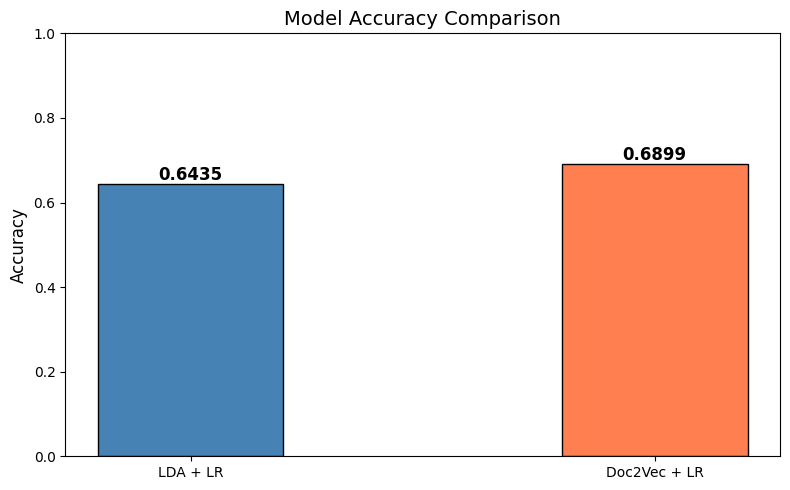

✅ Comparison complete!


In [15]:
# Summary Table
print("="*45)
print("      FINAL MODEL COMPARISON")
print("="*45)
print(f"{'Model':<30} {'Accuracy':>10}")
print("-"*45)
print(f"{'LDA + Logistic Regression':<30} {acc_lda:>10.4f}")
print(f"{'Doc2Vec + Logistic Regression':<30} {acc_d2v:>10.4f}")
print("="*45)

# Bar Chart
plt.figure(figsize=(8, 5))
model_names = ['LDA + LR', 'Doc2Vec + LR']
accuracies  = [acc_lda, acc_d2v]
colors      = ['steelblue', 'coral']

bars = plt.bar(model_names, accuracies,
               color=colors,
               edgecolor='black',
               width=0.4)

for bar, acc in zip(bars, accuracies):
    plt.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.01,
             f'{acc:.4f}',
             ha='center',
             fontsize=12,
             fontweight='bold')

plt.ylim(0, 1.0)
plt.ylabel("Accuracy", fontsize=12)
plt.title("Model Accuracy Comparison", fontsize=14)
plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150)
plt.show()

print("✅ Comparison complete!")

 Confusion Matrix

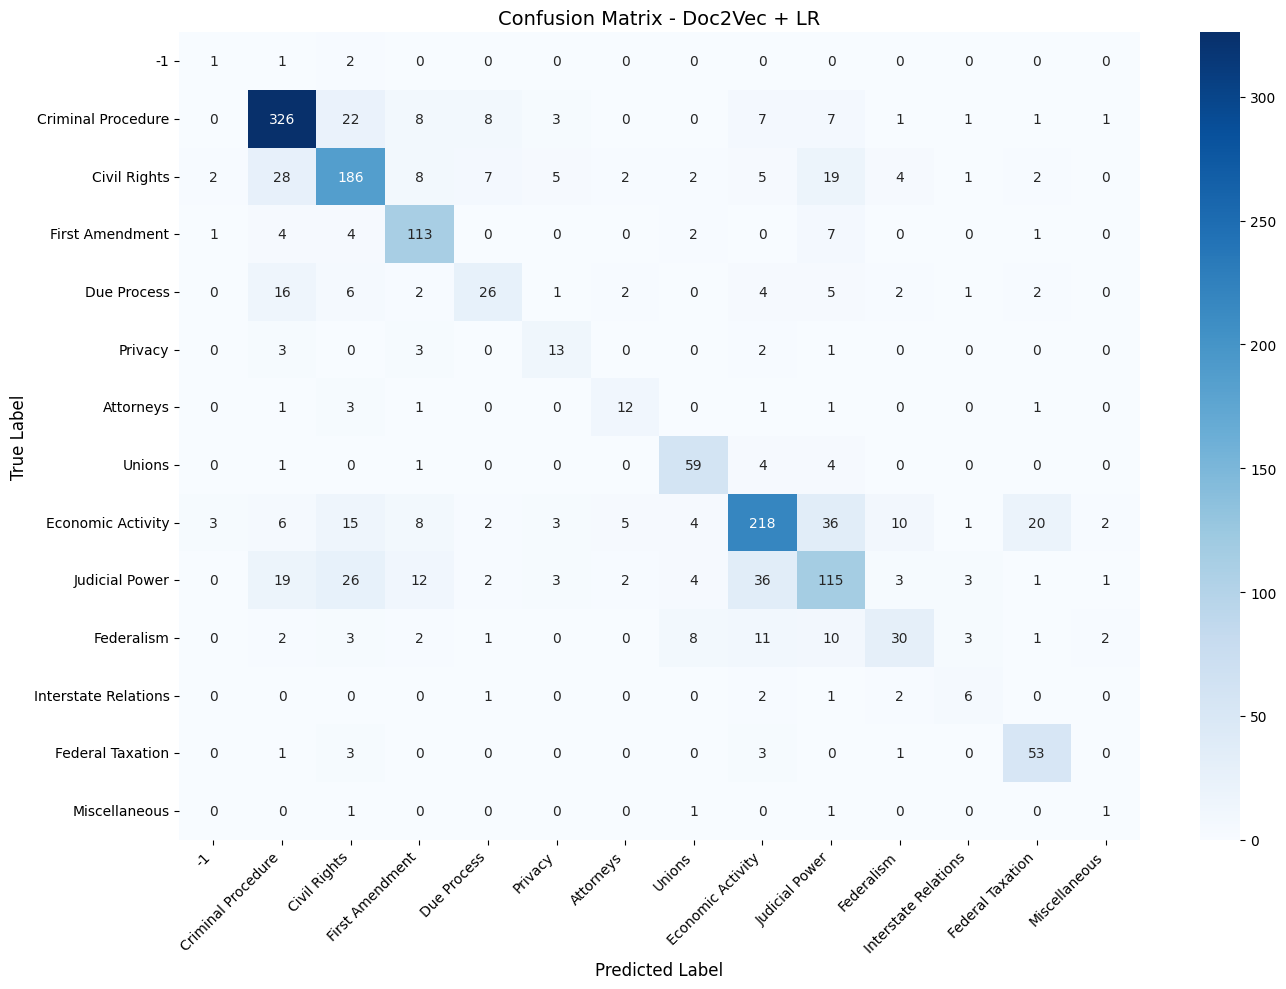

✅ Confusion matrix saved!


In [16]:
from sklearn.metrics import confusion_matrix

# Use best model
if acc_d2v > acc_lda:
    best_preds = y_pred_d2v
    best_name  = "Doc2Vec + LR"
else:
    best_preds = y_pred_lda
    best_name  = "LDA + LR"

label_names = [issue_area_labels.get(i, str(i))
               for i in sorted(set(y_test))]

cm = confusion_matrix(y_test, best_preds)

plt.figure(figsize=(14, 10))
sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Blues',
            xticklabels=label_names,
            yticklabels=label_names)

plt.title(f'Confusion Matrix - {best_name}', fontsize=14)
plt.ylabel('True Label', fontsize=12)
plt.xlabel('Predicted Label', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150)
plt.show()

print("✅ Confusion matrix saved!")

# Additional Visualizations

LDA Topics Visualization

In [19]:

print("TOP WORDS PER LDA TOPIC")
print("="*60)

for idx, topic in lda_model.print_topics(num_topics=5,
                                          num_words=8):
    print(f"\nTopic {idx+1}:")
    # Clean up the output
    words = [w.split('*')[1].strip().replace('"','')
             for w in topic.split('+')]
    print(f"  Words: {' | '.join(words)}")

TOP WORDS PER LDA TOPIC

Topic 6:
  Words: religious | religion | clause | church | establishment | gas | government | aid

Topic 13:
  Words: school | public | student | education | program | child | fund | speech

Topic 10:
  Words: amendment | power | constitutional | constitution | public | clause | congress | appellant

Topic 15:
  Words: trial | jury | defendant | counsel | judge | habeas | evidence | criminal

Topic 20:
  Words: jurisdiction | party | suit | relief | review | attorney | judicial | complaint


Per Class Performance

In [20]:
from sklearn.metrics import classification_report
import pandas as pd

# Get detailed report for both models
report_lda = classification_report(
    y_test, y_pred_lda,
    target_names=[issue_area_labels.get(i, str(i))
                  for i in sorted(set(y_test))],
    output_dict=True
)

report_d2v = classification_report(
    y_test, y_pred_d2v,
    target_names=[issue_area_labels.get(i, str(i))
                  for i in sorted(set(y_test))],
    output_dict=True
)

# Convert to DataFrame for nice display
report_lda_df = pd.DataFrame(report_lda).transpose()
report_d2v_df = pd.DataFrame(report_d2v).transpose()

print("LDA + LR - Per Class Results:")
print(report_lda_df.round(3))

print("\nDoc2Vec + LR - Per Class Results:")
print(report_d2v_df.round(3))

LDA + LR - Per Class Results:
                      precision  recall  f1-score   support
-1                        0.000   0.000     0.000     4.000
Criminal Procedure        0.760   0.906     0.827   385.000
Civil Rights              0.567   0.624     0.594   271.000
First Amendment           0.684   0.803     0.739   132.000
Due Process               0.250   0.015     0.028    67.000
Privacy                   0.250   0.045     0.077    22.000
Attorneys                 0.000   0.000     0.000    20.000
Unions                    0.633   0.725     0.676    69.000
Economic Activity         0.619   0.733     0.671   333.000
Judicial Power            0.541   0.551     0.546   227.000
Federalism                0.250   0.014     0.026    73.000
Interstate Relations      0.000   0.000     0.000    12.000
Federal Taxation          0.673   0.574     0.619    61.000
Miscellaneous             0.000   0.000     0.000     4.000
accuracy                  0.643   0.643     0.643     0.643
macro avg 

F1 Score Comparison Per Class

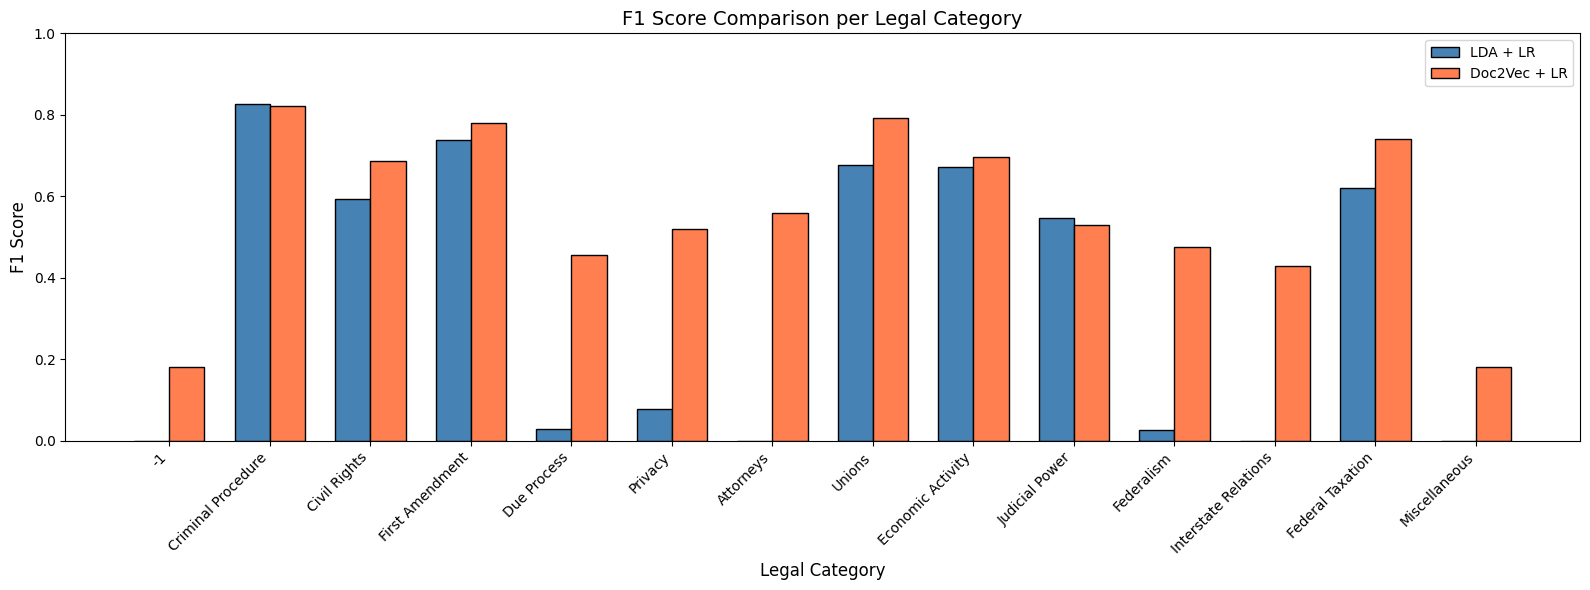

✅ F1 comparison plot saved!


In [21]:
# F1 Score per class - both models side by side
categories = [issue_area_labels.get(i, str(i))
              for i in sorted(set(y_test))]

f1_lda = [report_lda[cat]['f1-score']
          for cat in categories
          if cat in report_lda]

f1_d2v = [report_d2v[cat]['f1-score']
          for cat in categories
          if cat in report_d2v]

x = np.arange(len(categories))
width = 0.35

plt.figure(figsize=(16, 6))
bars1 = plt.bar(x - width/2, f1_lda, width,
                label='LDA + LR',
                color='steelblue',
                edgecolor='black')
bars2 = plt.bar(x + width/2, f1_d2v, width,
                label='Doc2Vec + LR',
                color='coral',
                edgecolor='black')

plt.xlabel('Legal Category', fontsize=12)
plt.ylabel('F1 Score', fontsize=12)
plt.title('F1 Score Comparison per Legal Category', fontsize=14)
plt.xticks(x, categories, rotation=45, ha='right')
plt.legend()
plt.ylim(0, 1.0)
plt.tight_layout()
plt.savefig('f1_comparison.png', dpi=150)
plt.show()

print("✅ F1 comparison plot saved!")

In [22]:
import pickle

# Save LDA model
lda_model.save(f'{save_path}lda_model')

# Save Doc2Vec model
doc2vec.save(f'{save_path}doc2vec_model')

# Save Logistic Regression models
with open(f'{save_path}lr_lda_model.pkl', 'wb') as f:
    pickle.dump(lr_lda, f)

with open(f'{save_path}lr_d2v_model.pkl', 'wb') as f:
    pickle.dump(lr_d2v, f)

# Save dictionary
dictionary.save(f'{save_path}dictionary.dict')

print("✅ All models saved!")

✅ All models saved!


# Test With a New Case

In [23]:
def predict_legal_category(new_text, model_type='doc2vec'):
    """
    Predict the legal category of a new case
    """
    # Preprocess
    tokens = preprocess_text(new_text)

    if model_type == 'lda':
        bow = dictionary.doc2bow(tokens)
        vector = np.array(get_topic_vector(bow)).reshape(1, -1)
        prediction = lr_lda.predict(vector)[0]
        confidence = lr_lda.predict_proba(vector).max()

    else:  # doc2vec
        vector = doc2vec.infer_vector(tokens).reshape(1, -1)
        prediction = lr_d2v.predict(vector)[0]
        confidence = lr_d2v.predict_proba(vector).max()

    category = issue_area_labels.get(prediction, 'Unknown')

    return prediction, category, confidence

# Test with a real example
test_case = """
The defendant was arrested without a warrant and
evidence was seized from his home. The court must
determine whether this violates the Fourth Amendment
protection against unreasonable searches and seizures.
The exclusionary rule prevents illegally obtained
evidence from being used in criminal proceedings.
"""

pred_label, pred_category, confidence = predict_legal_category(
    test_case,
    model_type='doc2vec'
)

print("="*50)
print("🔍 PREDICTION DEMO")
print("="*50)
print(f"Input text    : {test_case[:100]}...")
print(f"Predicted     : {pred_category}")
print(f"Label number  : {pred_label}")
print(f"Confidence    : {confidence:.2%}")
print("="*50)

🔍 PREDICTION DEMO
Input text    : 
The defendant was arrested without a warrant and 
evidence was seized from his home. The court must...
Predicted     : Judicial Power
Label number  : 9
Confidence    : 25.79%
